<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/HierarchicalManhattan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hierarchical Clustering — Manhattan

Metode **Agglomerative (bottom-up)**: awalnya setiap titik adalah cluster sendiri, lalu dua cluster terdekat digabung berulang-ulang sampai tersisa satu cluster. Proses penggabungan ini digambar sebagai **dendrogram**, yang dipakai untuk memilih jumlah cluster (fungsinya setara Elbow Method pada K-Means).

**Parameter yang dipakai:**
- `n_clusters = 3` — **disamakan** dengan k=3 dari Elbow Method K-Means dan target tuning eps DBSCAN, agar perbandingan **fair**.
- `linkage = 'average'` — jarak antar-cluster = rata-rata jarak semua pasangan titik. Dipilih karena valid untuk **ketiga distance metric** (linkage `ward` hanya valid untuk euclidean).
- `metric = 'manhattan'` — jarak antar-titik.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("Library siap.")

Library siap.


In [2]:
df = pd.read_csv('dataset_properti.csv')
print("Shape awal:", df.shape)
df.head()

Shape awal: (1530, 8)


,id_properti,lokasi,luas_m2,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga,kategori_harga
0,PROP0655,Tangerang,30.0,3,3.0,33.0,203754275,Murah
1,PROP0077,Bekasi,122.0,5,4.0,19.0,1058031695,Murah
2,PROP0317,Bekasi,142.8,1,1.0,9.0,1335792780,Mahal
3,PROP1348,Bekasi,152.6,4,3.0,6.0,1613770786,Mahal
4,PROP0572,Depok,61.2,1,1.0,9.0,522156222,Murah


In [3]:
# ============================================
# PREPROCESSING UNIVERSAL
# ============================================

df = df.drop(columns=['id_properti'])

before = len(df)
df = df.drop_duplicates()
print(f"[1] Hapus duplikat       : {before} -> {len(df)}")

df['luas_m2'] = df['luas_m2'].astype(str).str.replace(' m2', '', regex=False)
df['luas_m2'] = pd.to_numeric(df['luas_m2'], errors='coerce')

df['lokasi'] = df['lokasi'].str.strip().str.title()
df['lokasi'] = df['lokasi'].replace({'Jak. Utara': 'Jakarta Utara',
                                      'Jak. Selatan': 'Jakarta Selatan'})

numeric_cols = ['luas_m2', 'jumlah_kamar', 'jumlah_kamar_mandi',
                'usia_bangunan', 'harga']
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
print(f"[2] Missing values diisi  : {df[numeric_cols].isnull().sum().sum()} tersisa")

before = len(df)
df = df[df['harga'] < 100_000_000_000]
df = df[df['luas_m2'] < 1000]
print(f"[3] Hapus outlier ekstrem : {before} -> {len(df)}")

df = df.reset_index(drop=True)

FEATURES = ['luas_m2', 'jumlah_kamar', 'jumlah_kamar_mandi',
            'usia_bangunan', 'harga']
X = df[FEATURES].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"[4] Data siap clustering  : {X_scaled.shape}")
print(f"[5] Fitur                 : {FEATURES}")

[1] Hapus duplikat       : 1530 -> 1500
[2] Missing values diisi  : 0 tersisa
[3] Hapus outlier ekstrem : 1500 -> 1498
[4] Data siap clustering  : (1498, 5)
[5] Fitur                 : ['luas_m2', 'jumlah_kamar', 'jumlah_kamar_mandi', 'usia_bangunan', 'harga']


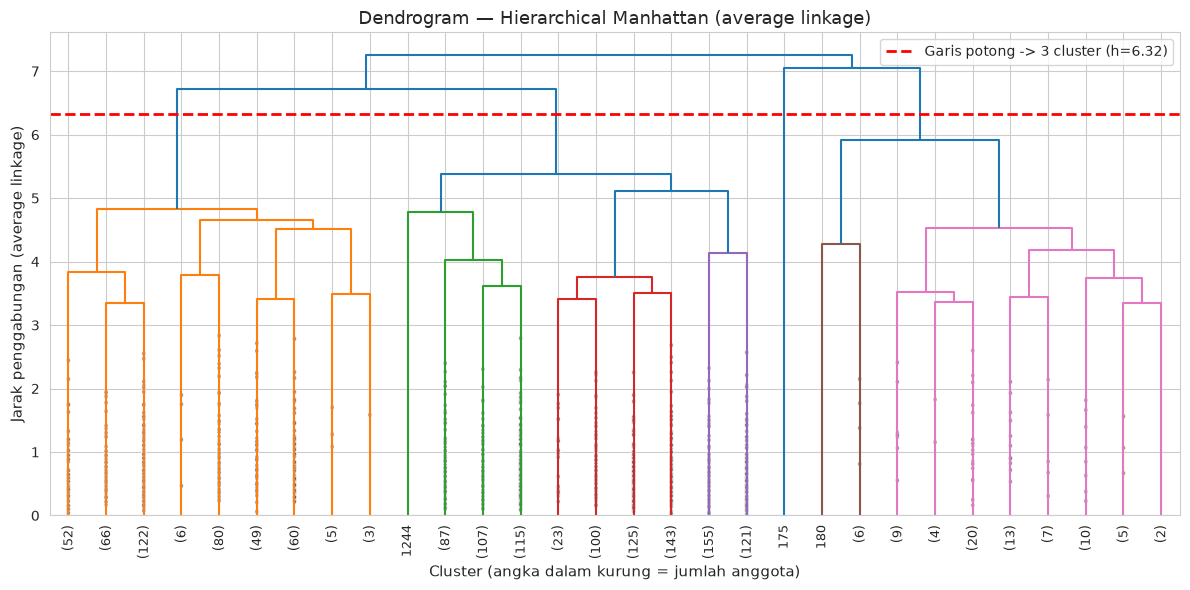

Ketinggian 6 penggabungan terakhir & besar lompatannya:
  h = 5.1193   (lompatan: 0.0000)
  h = 5.3871   (lompatan: 0.2678)
  h = 5.9109   (lompatan: 0.5238)
  h = 6.7259   (lompatan: 0.8150)
  h = 7.0562   (lompatan: 0.3303)
  h = 7.2497   (lompatan: 0.1935)

>> Dendrogram dipotong di ketinggian yang menghasilkan 3 cluster,
   disamakan dengan K-Means (elbow: k=3) & DBSCAN (tuning eps: 3 cluster).


In [4]:
# ============================================
# DENDROGRAM - pemilihan jumlah cluster
# (analogi Elbow Method pada K-Means)
# ============================================

# Hitung linkage: riwayat penggabungan cluster bottom-up
Z = linkage(X_scaled, method='average', metric='cityblock')  # scipy: manhattan = cityblock

# Plot dendrogram (tampilkan 30 penggabungan terakhir agar terbaca)
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90,
           leaf_font_size=9, show_contracted=True)

# Garis potong untuk 3 cluster:
# di antara ketinggian penggabungan ke-3 dan ke-4 terakhir
cut_height = (Z[-4, 2] + Z[-3, 2]) / 2
plt.axhline(y=cut_height, color='red', linestyle='--', linewidth=2,
            label=f'Garis potong -> 3 cluster (h={cut_height:.2f})')

plt.xlabel('Cluster (angka dalam kurung = jumlah anggota)', fontsize=11)
plt.ylabel('Jarak penggabungan (average linkage)', fontsize=11)
plt.title('Dendrogram — Hierarchical Manhattan (average linkage)', fontsize=13)
plt.legend()
plt.tight_layout()
plt.show()

# Lihat "lompatan jarak" pada penggabungan-penggabungan terakhir
print("Ketinggian 6 penggabungan terakhir & besar lompatannya:")
heights = Z[-6:, 2]
for i, h in enumerate(heights):
    gap = heights[i] - heights[i-1] if i > 0 else 0.0
    print(f"  h = {h:.4f}   (lompatan: {gap:.4f})")

print("\n>> Dendrogram dipotong di ketinggian yang menghasilkan 3 cluster,")
print("   disamakan dengan K-Means (elbow: k=3) & DBSCAN (tuning eps: 3 cluster).")

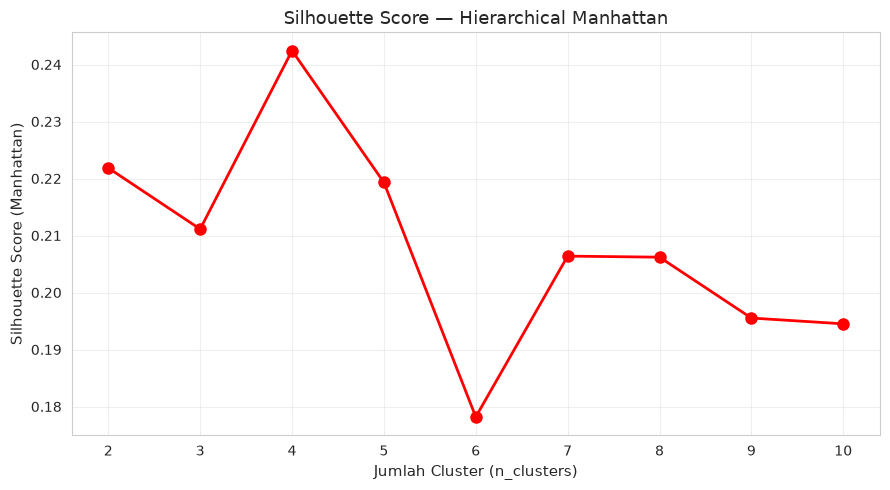

Silhouette Score per n_clusters:
  n_clusters=2: 0.2219
  n_clusters=3: 0.2111
  n_clusters=4: 0.2424
  n_clusters=5: 0.2193
  n_clusters=6: 0.1782
  n_clusters=7: 0.2064
  n_clusters=8: 0.2062
  n_clusters=9: 0.1955
  n_clusters=10: 0.1945

>> Silhouette tertinggi: n_clusters=4.
>> Tetap dipakai n_clusters=3 agar jumlah cluster SAMA di semua metode (fair comparison).


In [5]:
# Validasi: silhouette score untuk n_clusters = 2 sampai 10
# (paralel dengan silhouette scan pada notebook K-Means)
K_RANGE = range(2, 11)
sil_scores = []

for k in K_RANGE:
    agg = AgglomerativeClustering(n_clusters=k, metric='manhattan', linkage='average')
    labels_tmp = agg.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels_tmp, metric='manhattan')
    sil_scores.append(score)

plt.figure(figsize=(9, 5))
plt.plot(K_RANGE, sil_scores, 'ro-', linewidth=2, markersize=8)
plt.xlabel('Jumlah Cluster (n_clusters)', fontsize=11)
plt.ylabel('Silhouette Score (Manhattan)', fontsize=11)
plt.title('Silhouette Score — Hierarchical Manhattan', fontsize=13)
plt.xticks(K_RANGE)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Silhouette Score per n_clusters:")
for k, s in zip(K_RANGE, sil_scores):
    print(f"  n_clusters={k}: {s:.4f}")

print(f"\n>> Silhouette tertinggi: n_clusters={list(K_RANGE)[np.argmax(sil_scores)]}.")
print(">> Tetap dipakai n_clusters=3 agar jumlah cluster SAMA di semua metode (fair comparison).")

In [6]:
# ============================================
# PARAMETER
# ============================================
N_CLUSTERS = 3        # sama dengan k=3 (K-Means) & target 3 cluster (DBSCAN)
LINKAGE = 'average'   # valid untuk ketiga metric -> fair

# Tracking
tracemalloc.start()
start_time = time.time()

# Training
agg = AgglomerativeClustering(n_clusters=N_CLUSTERS, metric='manhattan', linkage=LINKAGE)
labels = agg.fit_predict(X_scaled)

exec_time = time.time() - start_time
_, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

df['cluster'] = labels

print("="*55)
print("HASIL HIERARCHICAL (MANHATTAN)")
print("="*55)
print(f"Jumlah cluster       : {N_CLUSTERS}")
print(f"Linkage              : {LINKAGE}")
print(f"Waktu eksekusi       : {exec_time:.4f} detik")
print(f"Peak memory          : {peak/1024:.2f} KB")
print("\nDistribusi cluster:")
print(df['cluster'].value_counts().sort_index())

HASIL HIERARCHICAL (MANHATTAN)
Jumlah cluster       : 3
Linkage              : average
Waktu eksekusi       : 0.0939 detik
Peak memory          : 9860.83 KB

Distribusi cluster:
cluster
0    1420
1      77
2       1
Name: count, dtype: int64


In [7]:
print("Rata-rata fitur per cluster:")
print(df.groupby('cluster')[FEATURES].mean().round(2))

Rata-rata fitur per cluster:
         luas_m2  jumlah_kamar  jumlah_kamar_mandi  usia_bangunan  \
cluster                                                             
0         106.46          2.98                2.54          19.65   
1         199.47          2.51                1.96          17.78   
2         278.70          3.00                3.00          34.00   

                harga  
cluster                
0        1.195813e+09  
1        2.729286e+09  
2        4.601143e+09  


In [8]:
print("\nDistribusi lokasi per cluster:")
print(pd.crosstab(df['cluster'], df['lokasi']))

print("\nDistribusi kategori harga per cluster:")
print(pd.crosstab(df['cluster'], df['kategori_harga']))


Distribusi lokasi per cluster:
lokasi   Bekasi  Bogor  Depok  Jakarta Selatan  Jakarta Utara  Tangerang
cluster                                                                 
0           258    266    241              187            230        238
1             9      2      6               37             13         10
2             0      0      0                1              0          0

Distribusi kategori harga per cluster:
kategori_harga  Mahal  Murah
cluster                     
0                 671    749
1                  77      0
2                   1      0


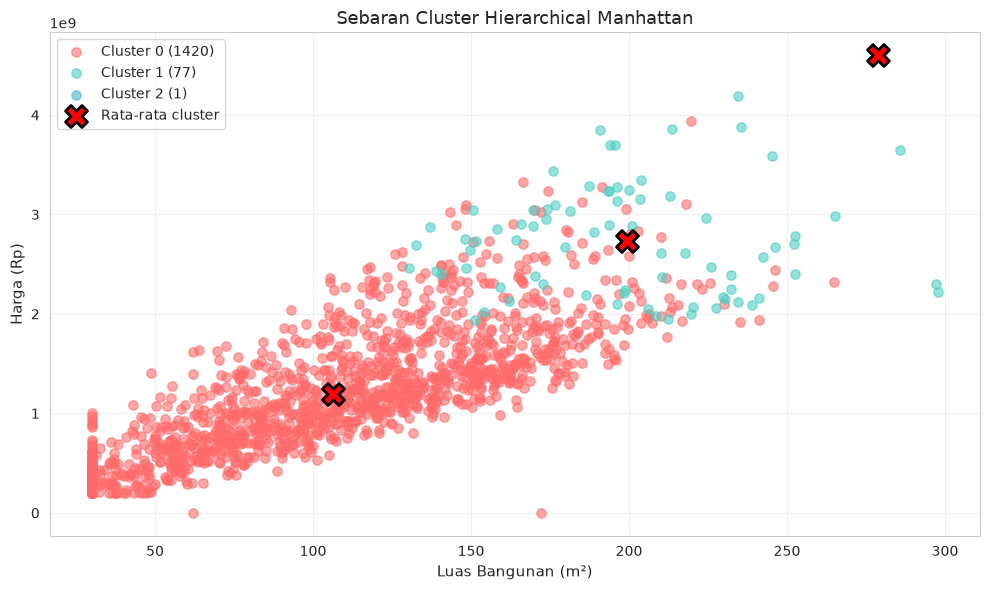

In [9]:
plt.figure(figsize=(10, 6))

# Warna per cluster
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7',
          '#DDA0DD', '#F0E68C', '#87CEEB', '#FFB6C1']

for i, label in enumerate(sorted(df['cluster'].unique())):
    subset = df[df['cluster'] == label]
    plt.scatter(subset['luas_m2'], subset['harga'],
                s=45, alpha=0.6, c=colors[i % len(colors)],
                label=f'Cluster {label} ({len(subset)})')

# Tandai rata-rata tiap cluster (hierarchical tidak punya centroid)
means = df.groupby('cluster')[['luas_m2', 'harga']].mean()
plt.scatter(means['luas_m2'], means['harga'],
            c='red', marker='X', s=250, edgecolor='black',
            linewidth=2, label='Rata-rata cluster', zorder=5)

plt.xlabel('Luas Bangunan (m²)', fontsize=11)
plt.ylabel('Harga (Rp)', fontsize=11)
plt.title('Sebaran Cluster Hierarchical Manhattan', fontsize=13)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

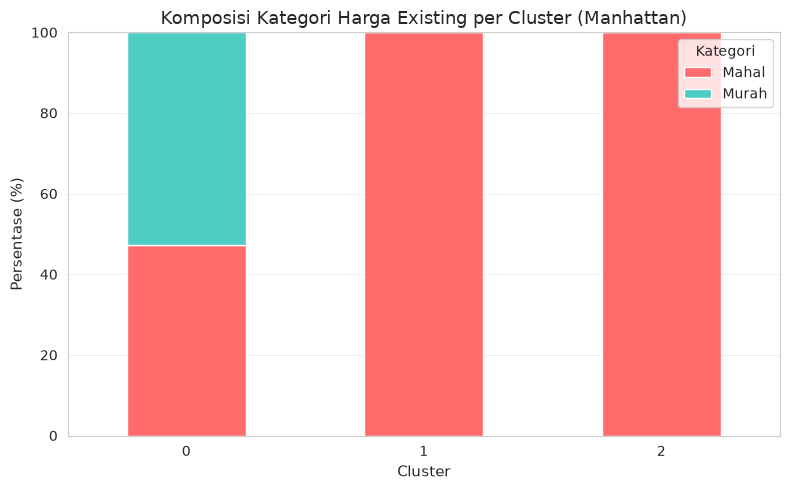


Persentase kategori harga per cluster (%):
kategori_harga   Mahal  Murah
cluster                      
0                47.25  52.75
1               100.00   0.00
2               100.00   0.00


In [10]:
comp = pd.crosstab(df['cluster'], df['kategori_harga'],
                   normalize='index') * 100

comp.plot(kind='bar', stacked=True, figsize=(8, 5),
          color=['#FF6B6B', '#4ECDC4'], edgecolor='white')
plt.xlabel('Cluster', fontsize=11)
plt.ylabel('Persentase (%)', fontsize=11)
plt.title('Komposisi Kategori Harga Existing per Cluster (Manhattan)', fontsize=13)
plt.legend(title='Kategori', loc='upper right')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nPersentase kategori harga per cluster (%):")
print(comp.round(2))

In [11]:
sil_final = silhouette_score(X_scaled, df['cluster'], metric='manhattan')
print(f"Silhouette Score Final (Manhattan): {sil_final:.4f}")

Silhouette Score Final (Manhattan): 0.2111


In [12]:
hasil_hierarchical_manhattan = {
    'Metode'              : 'Hierarchical',
    'Distance Metric'     : 'Manhattan',
    'Jumlah Cluster'      : N_CLUSTERS,
    'Jumlah Noise'        : 0,
    'Waktu Eksekusi (s)'  : round(exec_time, 4),
    'Peak Memory (KB)'    : round(peak / 1024, 2),
    'Silhouette Score'    : round(sil_final, 4),
    'Parameter'           : f'n_clusters={N_CLUSTERS}, linkage={LINKAGE}'
}

tabel = pd.DataFrame([hasil_hierarchical_manhattan])
print("="*60)
print("RINGKASAN METRIK — HIERARCHICAL MANHATTAN")
print("="*60)
tabel.T

RINGKASAN METRIK — HIERARCHICAL MANHATTAN


,0
Metode,Hierarchical
Distance Metric,Manhattan
Jumlah Cluster,3
Jumlah Noise,0
Waktu Eksekusi (s),0.0939
Peak Memory (KB),9860.83
Silhouette Score,0.2111
Parameter,"n_clusters=3, linkage=average"
